Inainte sa trimiti notebook-ul:

* asigura-te ca totul se executa cum trebuie. Prima oara, **restarteaza kernel-ul** (in meniu, selecteaza Kernel$\rightarrow$Restart & Run all);

* nu lasa niciun mesaj la output (`disp`, `printf`, linii care nu sunt incheiate cu `;`) in functiile pe care le scrii decat daca ti se specifica explicit sa faci acest lucru! Orice abatere va fi **depunctata automat** de grader;

* citeste instructiunile de [aici](https://github.com/radusqrt/numerical-methods/blob/master/lab_instructions.md) cu atentie;

* asigura-te ca rezolvi toate celulele in care scrie `YOUR CODE HERE` sau `YOUR ANSWER HERE` si ca iti treci numele mai jos:

In [1]:
STUDENT_NAME = "Andrei Ionescu";

---

# Laborator 12-13: Derivare numerică
### Autor: Radu Stochitoiu

## Functii ajutatoare

In [2]:
function plot_taylor(f, t0, x0, h, N, approx)
    xx = linspace(t0, t0 + N * h);
    hold;
    plot(xx, f(xx));
    plot([x0:h:x0+N*h], approx, '.', 'markersize', 14);
endfunction

## Problema 1

Implementati funcția ```taylor_1(df, t0, x0, h, N)``` ce primește un handle la o funcție $df$ de doi parametri ($t, x$) ce reprezintă derivata lui $x(t)$, un timp inițial $t_0$, o valoare inițială a lui $x(t_0) = x_0$, mărimea unui pas, $h$, și numărul total de pași, $N$, și returnează un vector linie cu toate valorile aproximate $x(t_k)$ cu $k = 0..N$.

Taylor 1 = Euler

In [5]:
function [values] = taylor_1(df, t0, x0, h, N)
    values = [x0];
    t = t0;
    x = x0;
    
    for i = 1:N
        % Aplicam dezvoltarea Taylor cu 1 componenta
        x = x + h * df(t, x);
        
        values = [values, x];
        t += h;
    endfor
endfunction

IndentationError: unexpected indent (<ipython-input-5-108f19434ddd>, line 2)

In [3]:
function [y] = f(t)
    y = t .* exp(-t);
endfunction

function [y] = df(t, x)
    y = -x + exp(-t);
endfunction

t0 = 0; x0 = 0; h = 0.5; N = 6;
res = taylor_1(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 1e-1);
subplot(4, 1, 1);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.1; N = 30;
res = taylor_1(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 0.11);
subplot(4, 1, 2);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.075; N = 40;
res = taylor_1(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 0.105);
subplot(4, 1, 3);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.1 / 3; N = 90;
res = taylor_1(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 0.07);
subplot(4, 1, 4);
plot_taylor(@f, t0, x0, h, N, res);

pos = get(gcf,'Position');
pos(3) *= 1.5;
pos(4) *= 3;
set(gcf, 'Position', pos);

IndentationError: unexpected indent (<ipython-input-3-b57ca48c504f>, line 2)

## Problema 2

Implementati funcția ```taylor_2(df, dfdt, dfdx, t0, x0, h, N)``` ce primește un handle la o funcție $df$ de doi parametri ($t, x$), ce reprezintă derivata lui $x(t)$, un handle la o funcție $dfdt$ (derivata parțială față de $t$ a lui $df$), un handle la o funcție $dfdx$ (derivata parțială față de $x$ a lui $df$), un timp inițial $t_0$, o valoare inițială a lui $x(t_0) = x_0$, mărimea unui pas, $h$, și numărul total de pași, $N$, și returnează un vector linie cu toate valorile aproximate $x(t_k)$ cu $k = 0..N$.

In [5]:
function [values] = taylor_2(df, dfdt, dfdx, t0, x0, h, N)
    values = [x0];
    t = t0;
    x = x0;
    
    for i = 1:N
        f = df(t, x);
        % Aplicam dezvoltarea Taylor cu 2 termeni
        x = x + h * f + 0.5 * h * h * (dfdt(t, x) + dfdx(t, x) * f);
        
        values = [values, x];
        t += h;
    endfor
endfunction 

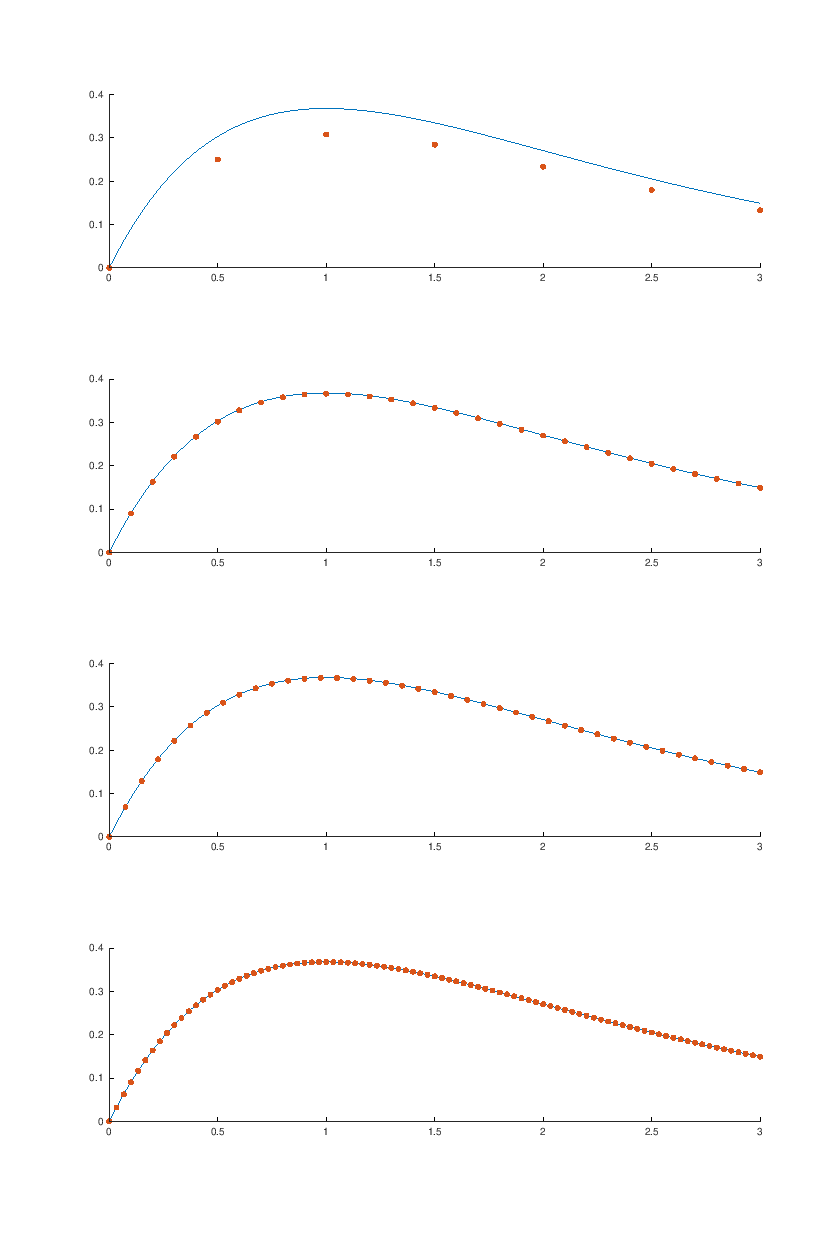

In [6]:
function [y] = f(t)
    y = t .* exp(-t);
endfunction

function [y] = df(t, x)
    y = -x + exp(-t);
endfunction

function[y] = dfdt(t)
    y = -exp(-t);
endfunction

function[y] = dfdx(x)
    y = -1;
endfunction

t0 = 0; x0 = 0; h = 0.5; N = 6;
res = taylor_2(@df, @dfdt, @dfdx, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-2);
subplot(4, 1, 1);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.1; N = 30;
res = taylor_2(@df, @dfdt, @dfdx, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-3);
subplot(4, 1, 2);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.075; N = 40;
res = taylor_2(@df, @dfdt, @dfdx, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-4);
subplot(4, 1, 3);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.1 / 3; N = 90;
res = taylor_2(@df, @dfdt, @dfdx, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-5);
subplot(4, 1, 4);
plot_taylor(@f, t0, x0, h, N, res);

pos = get(gcf,'Position');
pos(3) *= 1.5;
pos(4) *= 3;
set(gcf, 'Position', pos);

## Problema 3

Implementati funcția ```rk2_heun(df, t0, x0, h, N)``` ce primește un handle la o funcție $df$ de doi parametri ($t, x$), ce reprezintă derivata lui $x(t)$, un timp inițial $t_0$, o valoare inițială a lui $x(t_0) = x_0$, mărimea unui pas, $h$, și numărul total de pași, $N$, și returnează un vector linie cu toate valorile aproximate $x(t_k)$ cu $k = 0..N$.

In [7]:
function [values] = rk2_heun(df, t0, x0, h, N)
    values = [x0];
    t = t0;
    x = x0;
    
    for i = 1:N
        % Aproximam al 2-lea termen din Taylor la pasul curent si cel viitor
        k1 = h * df(t, x);
        t += h;
        k2 = h * df(t, x+k1);
        % x_i + (x_{i+1} - x_i), al doilea termen vine din integrare prin
        % regula trapezelor
        x = x + 0.5 * (k1 + k2);
        
        values = [values, x];
    endfor
endfunction

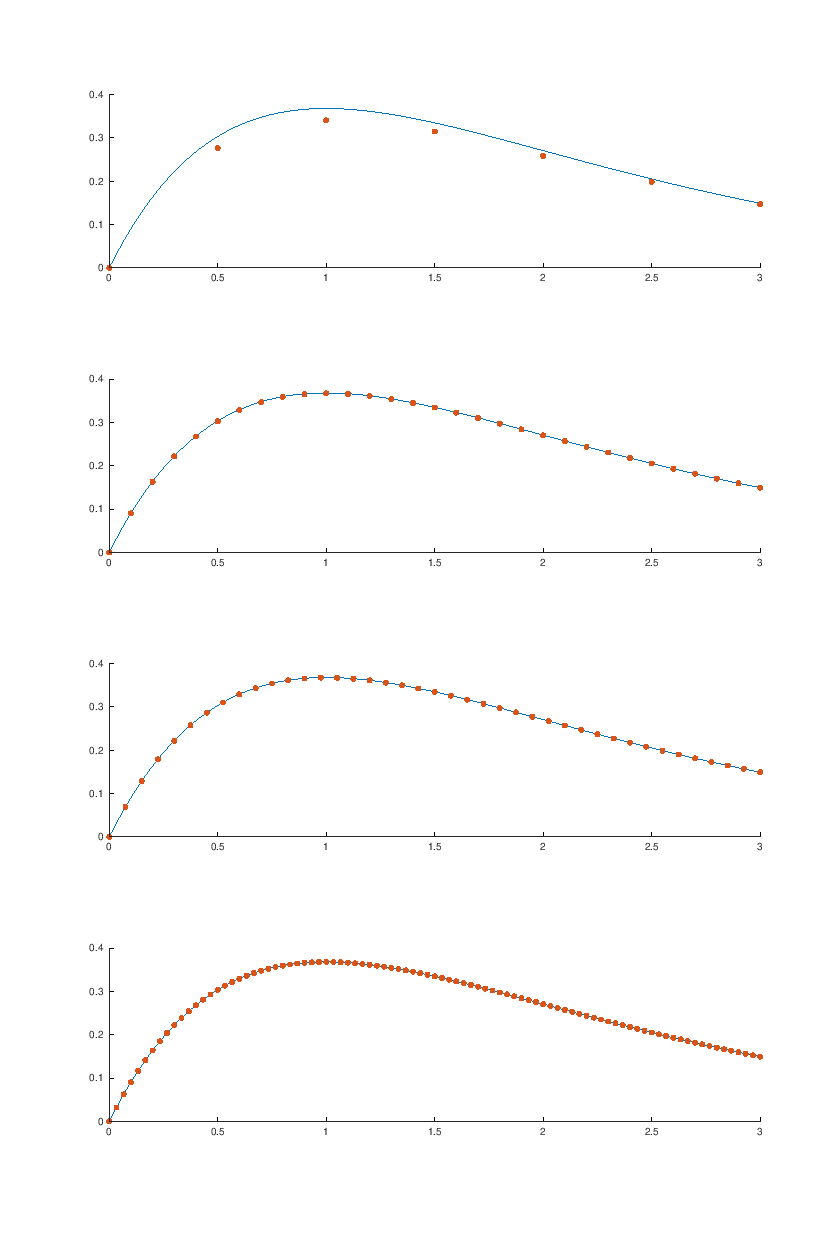

In [8]:
function [y] = f(t)
    y = t .* exp(-t);
endfunction

function [y] = df(t, x)
    y = -x + exp(-t);
endfunction

t0 = 0; x0 = 0; h = 0.5; N = 6;
res = rk2_heun(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 1e-2);
subplot(4, 1, 1);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.1; N = 30;
res = rk2_heun(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 1e-4);
subplot(4, 1, 2);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.075; N = 40;
res = rk2_heun(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-4);
subplot(4, 1, 3);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.1 / 3; N = 90;
res = rk2_heun(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-5);
subplot(4, 1, 4);
plot_taylor(@f, t0, x0, h, N, res);

pos = get(gcf,'Position');
pos(3) *= 1.5;
pos(4) *= 3;
set(gcf, 'Position', pos);

## Problema 4

Implementati funcția ```rk4_classic(df, t0, x0, h, N)``` ce primește un handle la o funcție $df$ de doi parametri ($t, x$), ce reprezintă derivata lui $x(t)$, un timp inițial $t_0$, o valoare inițială a lui $x(t_0) = x_0$, mărimea unui pas, $h$, și numărul total de pași, $N$, și returnează un vector linie cu toate valorile aproximate $x(t_k)$ cu $k = 0..N$.

In [9]:
function [values] = rk4_classic(df, t0, x0, h, N)
    values = [x0];
    t = t0;
    x = x0;
    
    for i = 1:N
        % Aproximam al 2-lea termen din Taylor la pasul curent si cel viitor
        k1 = h * df(t, x);
        k2 = h * df(t + h/2, x + k1/2);
        k3 = h * df(t + h/2, x + k2/2);
        k4 = h * df(t + h, x + k3);
        % x_i + (x_{i+1} - x_i), al doilea termen vine din integrare prin
        % metoda Simpson
        x = x + (k1 + 2 * k2 + 2 * k3 + k4) / 6;
        
        t += h;
        values = [values, x];
    endfor
endfunction

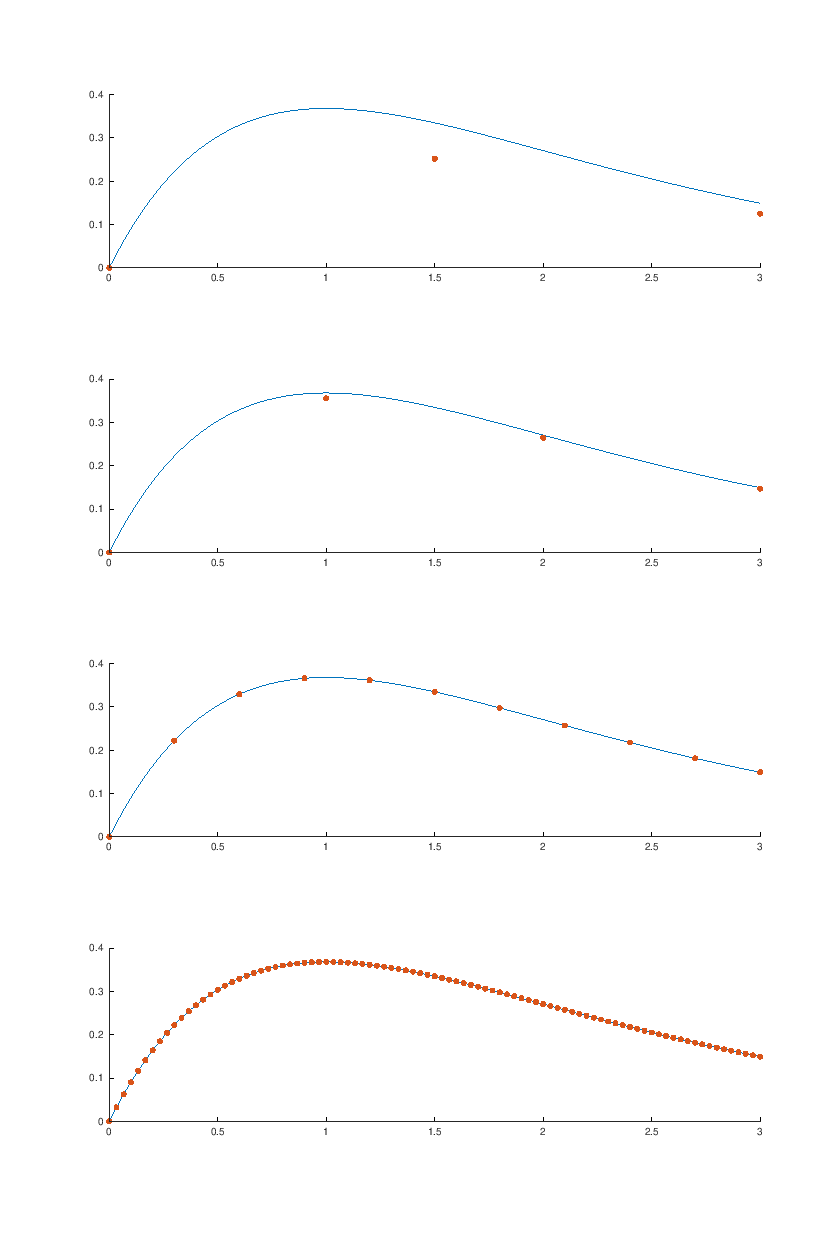

In [10]:
function [y] = f(t)
    y = t .* exp(-t);
endfunction

function [y] = df(t, x)
    y = -x + exp(-t);
endfunction

t0 = 0; x0 = 0; h = 1.5; N = 2;
res = rk4_classic(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-2);
subplot(4, 1, 1);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 1; N = 3;
res = rk4_classic(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-3);
subplot(4, 1, 2);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.3; N = 10;
res = rk4_classic(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-5);
subplot(4, 1, 3);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.1 / 3; N = 90;
res = rk4_classic(@df, t0, x0, h, N);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-10);
subplot(4, 1, 4);
plot_taylor(@f, t0, x0, h, N, res);

pos = get(gcf,'Position');
pos(3) *= 1.5;
pos(4) *= 3;
set(gcf, 'Position', pos);

## Problema 5

Implementati funcția ```ab2_explicit(df, t0, x0, h, N, initial_approximator)``` ce primește un handle la o funcție $df$ de doi parametri ($t, x$), ce reprezintă derivata lui $x(t)$, un timp inițial $t_0$, o valoare inițială a lui $x(t_0) = x_0$, mărimea unui pas, $h$, numărul total de pași, $N$, și un handle la o funcție ce va fi folosită pentru aproximarea inițială a lui $x_1$ și returnează un vector linie cu toate valorile aproximate $x(t_k)$ cu $k = 0..N$.

In [11]:
function [values] = ab2_explicit(df, t0, x0, h, N, initial_approximator)
    t = t0 + h;
    x = initial_approximator(df, t0, x0, h, 1)(2);
    values = [x0, x];
    % f_{i-1}
    prev_f = df(t0, x0);
    
    for i = 2:N
        f = df(t, x);
        x = x + h / 2 * (3 * f - prev_f);
        
        prev_f = f;
        t += h;
        values = [values, x];
    endfor
endfunction

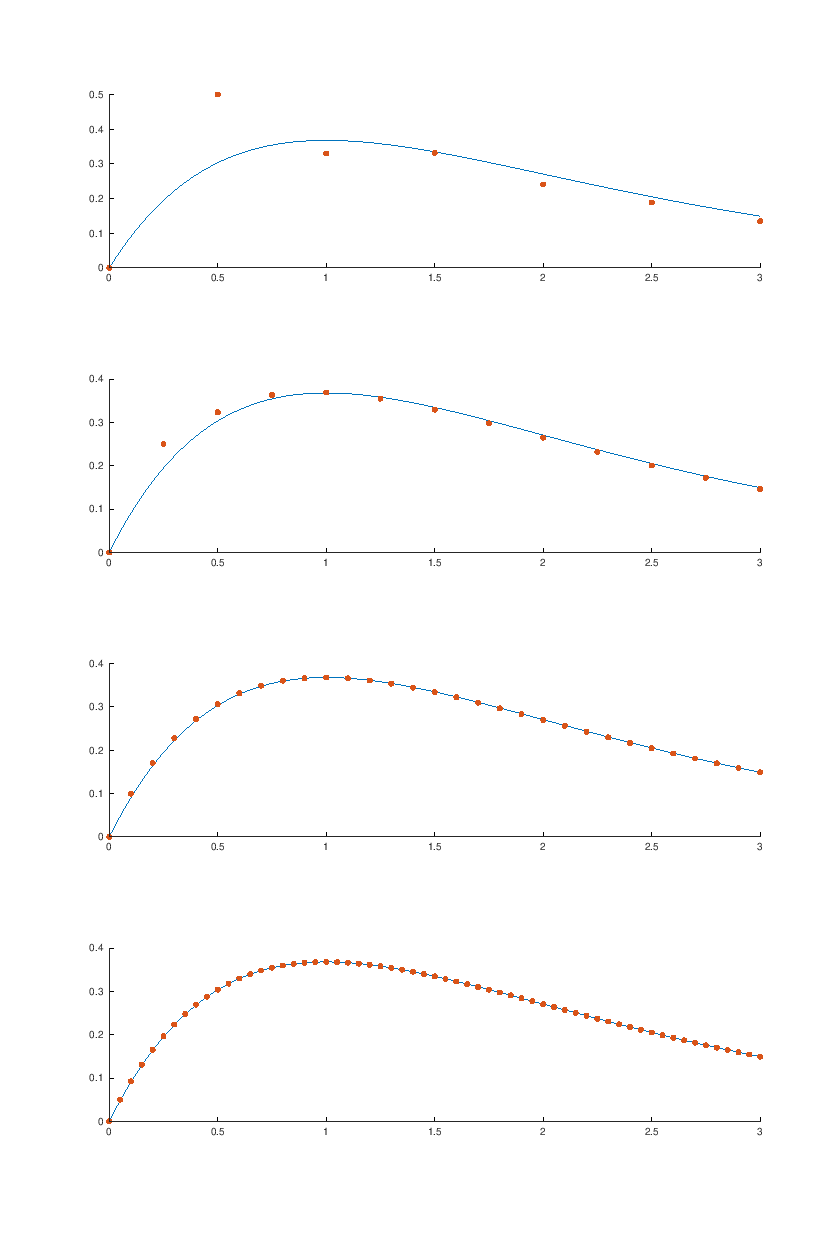

In [12]:
function [y] = f(t)
    y = t .* exp(-t);
endfunction

function [y] = df(t, x)
    y = -x + exp(-t);
endfunction

t0 = 0; x0 = 0; h = 0.5; N = 6;
res = ab2_explicit(@df, t0, x0, h, N, @taylor_1);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 1e-1);
subplot(4, 1, 1);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.25; N = 12;
res = ab2_explicit(@df, t0, x0, h, N, @taylor_1);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 1e-2);
subplot(4, 1, 2);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.1; N = 30;
res = ab2_explicit(@df, t0, x0, h, N, @taylor_1);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-4);
subplot(4, 1, 3);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.05; N = 60;
res = ab2_explicit(@df, t0, x0, h, N, @taylor_1);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 1e-4);
subplot(4, 1, 4);
plot_taylor(@f, t0, x0, h, N, res);

pos = get(gcf,'Position');
pos(3) *= 1.5;
pos(4) *= 3;
set(gcf, 'Position', pos);

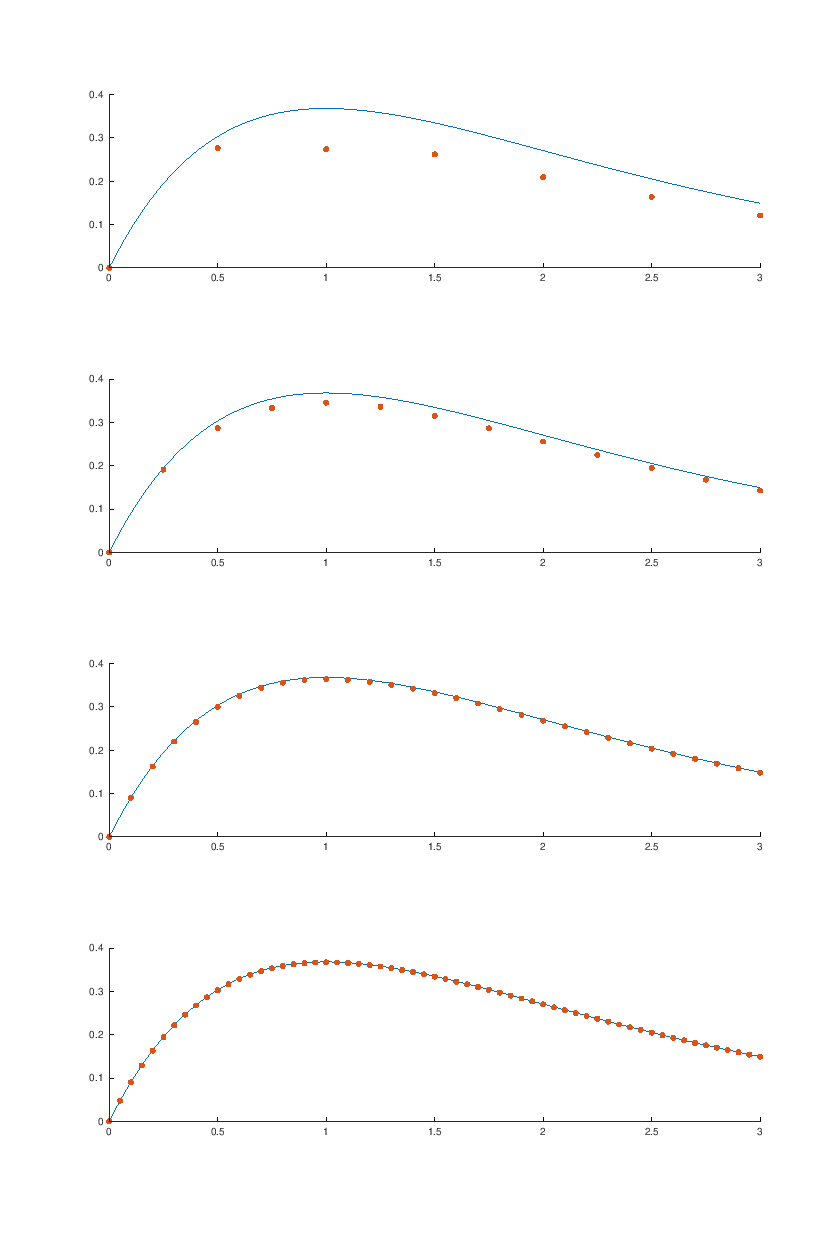

In [13]:
function [y] = f(t)
    y = t .* exp(-t);
endfunction

function [y] = df(t, x)
    y = -x + exp(-t);
endfunction

t0 = 0; x0 = 0; h = 0.5; N = 6;
res = ab2_explicit(@df, t0, x0, h, N, @rk2_heun);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-1);
subplot(4, 1, 1);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.25; N = 12;
res = ab2_explicit(@df, t0, x0, h, N, @rk2_heun);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-2);
subplot(4, 1, 2);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.1; N = 30;
res = ab2_explicit(@df, t0, x0, h, N, @rk2_heun);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-4);
subplot(4, 1, 3);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.05; N = 60;
res = ab2_explicit(@df, t0, x0, h, N, @rk2_heun);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 1e-4);
subplot(4, 1, 4);
plot_taylor(@f, t0, x0, h, N, res);

pos = get(gcf,'Position');
pos(3) *= 1.5;
pos(4) *= 3;
set(gcf, 'Position', pos);

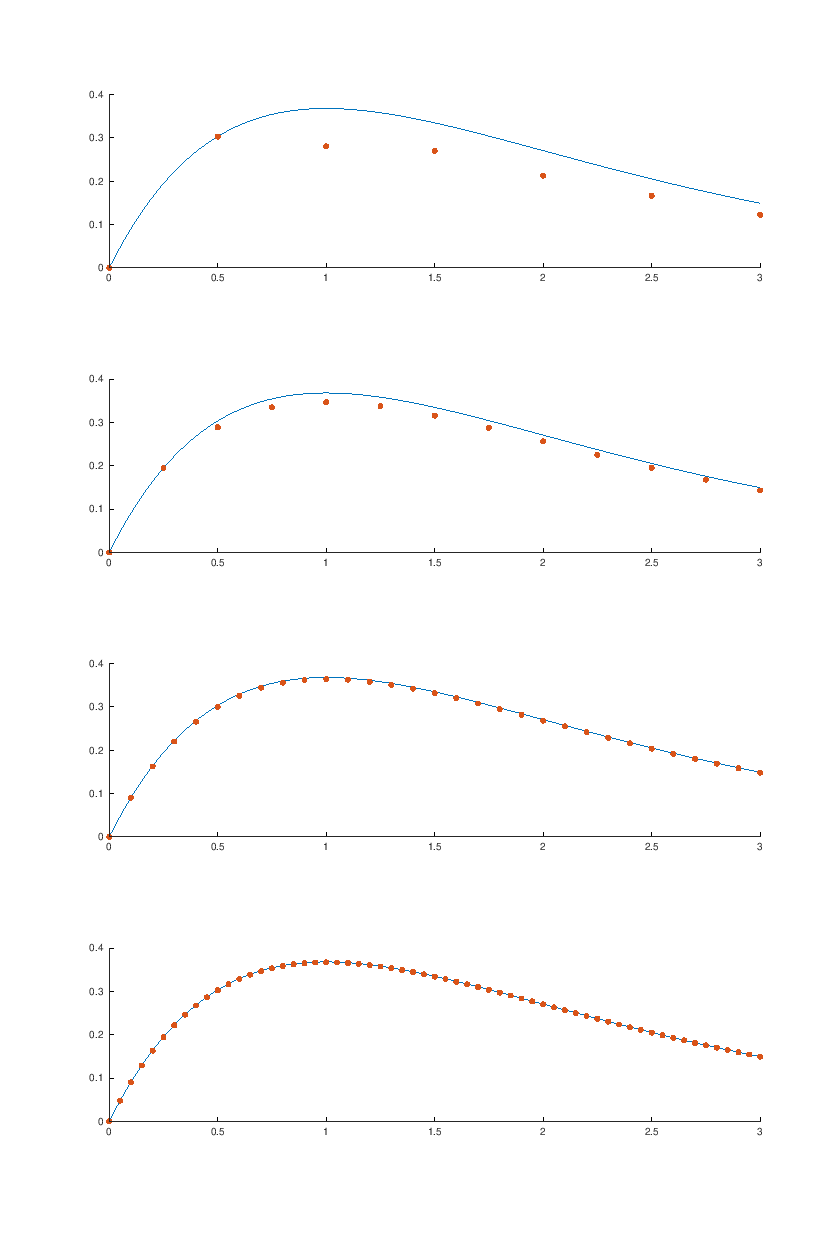

In [14]:
function [y] = f(t)
    y = t .* exp(-t);
endfunction

function [y] = df(t, x)
    y = -x + exp(-t);
endfunction

t0 = 0; x0 = 0; h = 0.5; N = 6;
res = ab2_explicit(@df, t0, x0, h, N, @rk4_classic);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-2);
subplot(4, 1, 1);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.25; N = 12;
res = ab2_explicit(@df, t0, x0, h, N, @rk4_classic);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-2);
subplot(4, 1, 2);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.1; N = 30;
res = ab2_explicit(@df, t0, x0, h, N, @rk4_classic);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-4);
subplot(4, 1, 3);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.05; N = 60;
res = ab2_explicit(@df, t0, x0, h, N, @rk4_classic);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 1e-4);
subplot(4, 1, 4);
plot_taylor(@f, t0, x0, h, N, res);

pos = get(gcf,'Position');
pos(3) *= 1.5;
pos(4) *= 3;
set(gcf, 'Position', pos);

## Problema 6

Implementati funcția ```abm_multistep(df, t0, x0, h, N, initial_approximator)``` ce primește un handle la o funcție $df$ de doi parametri ($t, x$), ce reprezintă derivata lui $x(t)$, un timp inițial $t_0$, o valoare inițială a lui $x(t_0) = x_0$, mărimea unui pas, $h$, numărul total de pași, $N$, și un handle la o funcție ce va fi folosită pentru aproximarea inițială a lui $x_1$ și returnează un vector linie cu toate valorile aproximate $x(t_k)$ cu $k = 0..N$.

In [15]:
function [values] = abm_multistep(df, t0, x0, h, N, initial_approximator)
    t = t0 + h;
    x = initial_approximator(df, t0, x0, h, 1)(2);
    values = [x0, x];
    % f_{i-1}
    prev_f = df(t0, x0);
    
    for i = 2:N
        f = df(t, x);
        % Adam-Bashforth2 explicit, gasim predictori
        x_pred = x + h / 2 * (3 * f - prev_f);
        f_pred = df(t+h, x_pred);
        % AB-Moulton implicit, corectam
        x = x + h / 2 * (f_pred + f);
        
        prev_f = f;
        t += h;
        values = [values, x];
    endfor
endfunction

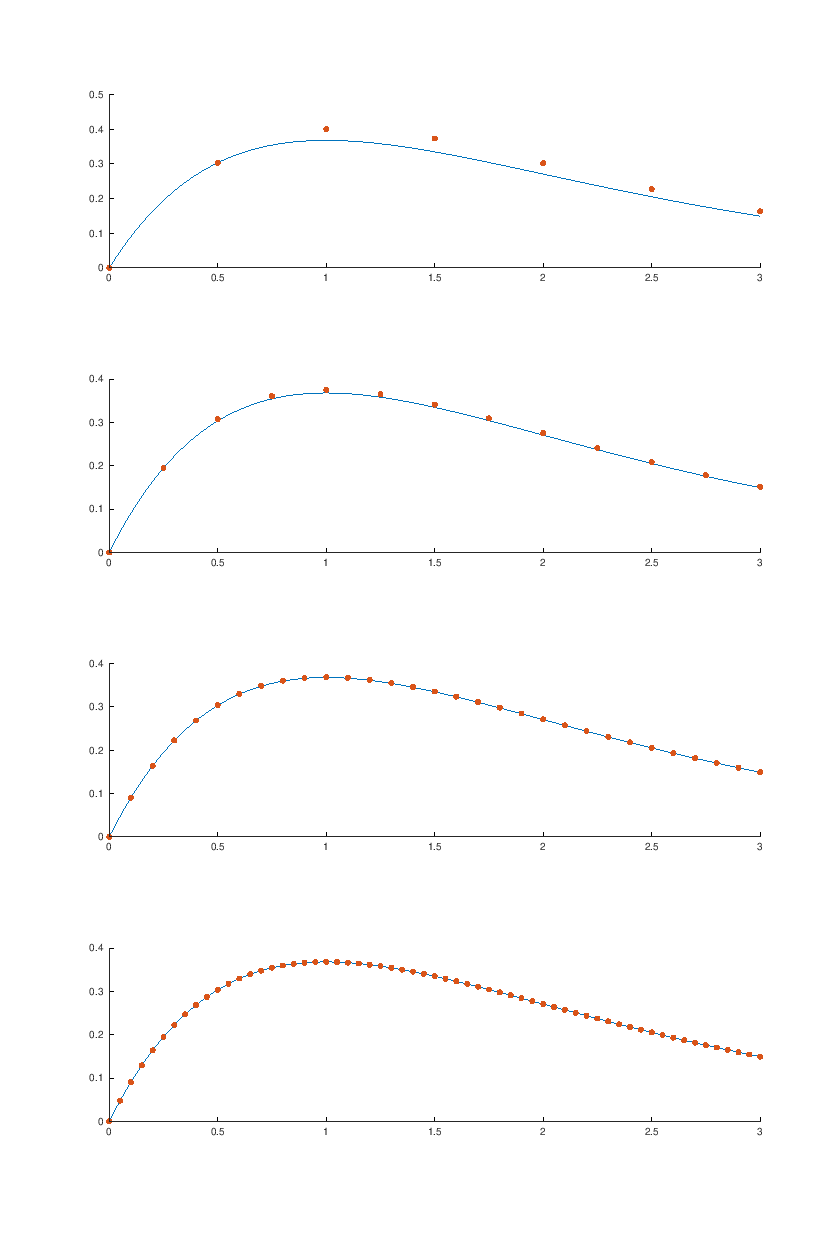

In [16]:
function [y] = f(t)
    y = t .* exp(-t);
endfunction

function [y] = df(t, x)
    y = -x + exp(-t);
endfunction

t0 = 0; x0 = 0; h = 0.5; N = 6;
res = abm_multistep(@df, t0, x0, h, N, @rk4_classic);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-2);
subplot(4, 1, 1);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.25; N = 12;
res = abm_multistep(@df, t0, x0, h, N, @rk4_classic);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-2);
subplot(4, 1, 2);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.1; N = 30;
res = abm_multistep(@df, t0, x0, h, N, @rk4_classic);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-4);
subplot(4, 1, 3);
plot_taylor(@f, t0, x0, h, N, res);

t0 = 0; x0 = 0; h = 0.05; N = 60;
res = abm_multistep(@df, t0, x0, h, N, @rk4_classic);
err = norm(res - f([t0:h:t0+N*h]));
assert(err / N < 5e-5);
subplot(4, 1, 4);
plot_taylor(@f, t0, x0, h, N, res);

pos = get(gcf,'Position');
pos(3) *= 1.5;
pos(4) *= 3;
set(gcf, 'Position', pos);